# HW2 Part 2: Single-Stock Risk Report

Parameterized template, executed per ticker by `03_run_all_stocks.py`. Uses `ohlc_hw_cleaned`.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import scrapbook as sb
from IPython.display import display

%matplotlib inline

## 2.1 Parameters

The next cell carries the `parameters` tag so papermill can override it.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # Database with ohlc_hw_cleaned

In [3]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/terencechiu/Developer/Berkeley/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Terence_Chiu/data/data.db"


## 2.2 Data loading

- [ ] Load `ohlc_hw_cleaned` for `ticker` between `start_date` and `end_date`
- [ ] Print "{Ticker} from {start} to {end}: {N} trading days"
- [ ] Head and tail, plus actual first/last observation dates
- [ ] Validate input; fail clearly on insufficient history (20 returns need ≥ 21 prices)

In [4]:
VOLATILITY_WINDOW = 20  # 20 returns need at least 21 prices
MA_WINDOW = 50

database = Path(db_path).expanduser().resolve()
if not database.is_file():
    raise FileNotFoundError(f"Database not found at {database}. Run 01_data_cleaning.ipynb first.")
if pd.Timestamp(start_date) > pd.Timestamp(end_date):
    raise ValueError("start_date must be on or before end_date.")

query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
# Read-only connection: the report never changes the database.
with closing(sqlite3.connect(database.as_uri() + "?mode=ro", uri=True)) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table'", conn)["name"]
    if "ohlc_hw_cleaned" not in set(tables):
        raise ValueError("Table ohlc_hw_cleaned not found. Run 01_data_cleaning.ipynb first.")
    df = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date),
                           parse_dates=["ts"], index_col="ts")

# Validate the input before calculating anything
if df.empty:
    raise ValueError(f"No cleaned data for {ticker} between {start_date} and {end_date}.")
if len(df) < VOLATILITY_WINDOW + 1:
    raise ValueError(f"{ticker}: need at least {VOLATILITY_WINDOW + 1} prices for a "
                     f"{VOLATILITY_WINDOW}-return window; got {len(df)}.")
if df.index.duplicated().any():
    raise ValueError(f"{ticker}: duplicate dates in ohlc_hw_cleaned.")
if not (np.isfinite(df["adj_close"]) & df["adj_close"].gt(0)).all():
    raise ValueError(f"{ticker}: adjusted close must be finite and positive.")

first_date, last_date = df.index.min().date(), df.index.max().date()
print(f"{ticker} from {start_date} to {end_date}: {len(df)} trading days")
print(f"Actual coverage: {first_date} to {last_date}")
if pd.Timestamp(last_date) < pd.Timestamp(end_date):
    print(f"Note: the supplied history ends on {last_date}, before the requested end date.")
display(df.head())
display(df.tail())

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual coverage: 2024-06-03 to 2024-11-29
Note: the supplied history ends on 2024-11-29, before the requested end date.


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,168.18,171.31,168.06,170.01,167.22,3475500


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,227.75,230.36,227.19,227.41,227.41,2640300


## 2.3 Risk metrics

Use **adjusted close** and daily **log returns**. Sharpe uses a 2% annual risk-free rate. Return `NaN` for zero volatility or too few returns. Keep fractions; format percentages only for display.

In [5]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns.

    log(price / previous price). The first value is NaN because it has no
    previous price; it is not a zero-return day.
    """
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility.

    Sample standard deviation of the last `window` daily log returns, times
    sqrt(252). The warm-up values stay NaN until a full window exists.
    """
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak.

    Fractions <= 0. The maximum drawdown over the period is `.min()` of this Series.
    """
    running_peak = prices.cummax()
    return (prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio from daily log returns.

    Course approximation: (mean * 252 - rf) / (std * sqrt(252)).
    Returns NaN with fewer than two returns or zero / undefined volatility.
    """
    observed = returns.dropna()
    sigma = observed.std()
    if len(observed) < 2 or not np.isfinite(sigma) or np.isclose(sigma, 0):
        return np.nan
    return (observed.mean() * 252 - risk_free_rate) / (sigma * np.sqrt(252))

In [6]:
# Apply the functions and display the results
df["log_return"] = calculate_returns(df["adj_close"])
df["volatility"] = calculate_volatility(df["log_return"], VOLATILITY_WINDOW)
df["sma_50"] = df["adj_close"].rolling(MA_WINDOW).mean()
df["drawdown"] = calculate_max_drawdown(df["adj_close"])

log_returns = df["log_return"].dropna()  # the first price has no return
sharpe_ratio = calculate_sharpe_ratio(log_returns)
max_drawdown = df["drawdown"].min()

# Hand-checkable examples: 80 -> 100 -> 70 -> 85 has worst drawdown -30%, final -15%
example = calculate_max_drawdown(pd.Series([80.0, 100.0, 70.0, 85.0]))
assert np.isclose(example.min(), -0.30) and np.isclose(example.iloc[-1], -0.15)
assert pd.isna(calculate_sharpe_ratio(pd.Series([0.01, 0.01])))  # zero volatility
assert df["volatility"].iloc[:VOLATILITY_WINDOW].isna().all()  # warm-up kept as NaN

display(df[["adj_close", "log_return", "volatility", "sma_50", "drawdown"]].tail())
print("Sharpe ratio:", "N/A" if pd.isna(sharpe_ratio) else f"{sharpe_ratio:.2f}")
print(f"Maximum drawdown: {max_drawdown:.2%}")
if df["sma_50"].isna().all():
    print(f"Only {len(df)} prices: the 50-day moving average needs 50, so it is not shown.")

,adj_close,log_return,volatility,sma_50,drawdown
ts,,,,,
2024-11-22,222.97,0.002560,0.241515,218.0336,-0.044769
2024-11-25,226.13,0.014073,0.241623,218.2470,-0.031231
2024-11-26,228.83,0.011869,0.236457,218.5744,-0.019664
2024-11-27,226.92,-0.008382,0.212190,218.8476,-0.027847
2024-11-29,227.41,0.002157,0.212125,219.1514,-0.025748


Sharpe ratio: 3.22
Maximum drawdown: -12.90%


## 2.4 Visualization

2×2 grid, `figsize=(16, 12)`, grid and axis labels on every panel, one colour scheme. Main title: "{Ticker} Risk Analysis Report - {start_date} to {end_date}".

- [ ] **Top left:** adjusted close coloured by volatility (red > mean, green ≤ mean, gray warm-up) plus 50-day MA. "{Ticker} Price and 50-day MA"
- [ ] **Top right:** daily-return bars (green +, red −), line at 0. "{Ticker} Daily Returns"
- [ ] **Bottom left:** 20-day rolling vol, mean line, shaded high/low regions. "{Ticker} Rolling Volatility (20-day)"
- [ ] **Bottom right:** drawdown area below 0, red/pink fill, max-drawdown point marked. "{Ticker} Maximum Drawdown"
- [ ] Don't fill warm-up gaps with zero; explain a missing 50-day MA on short reports

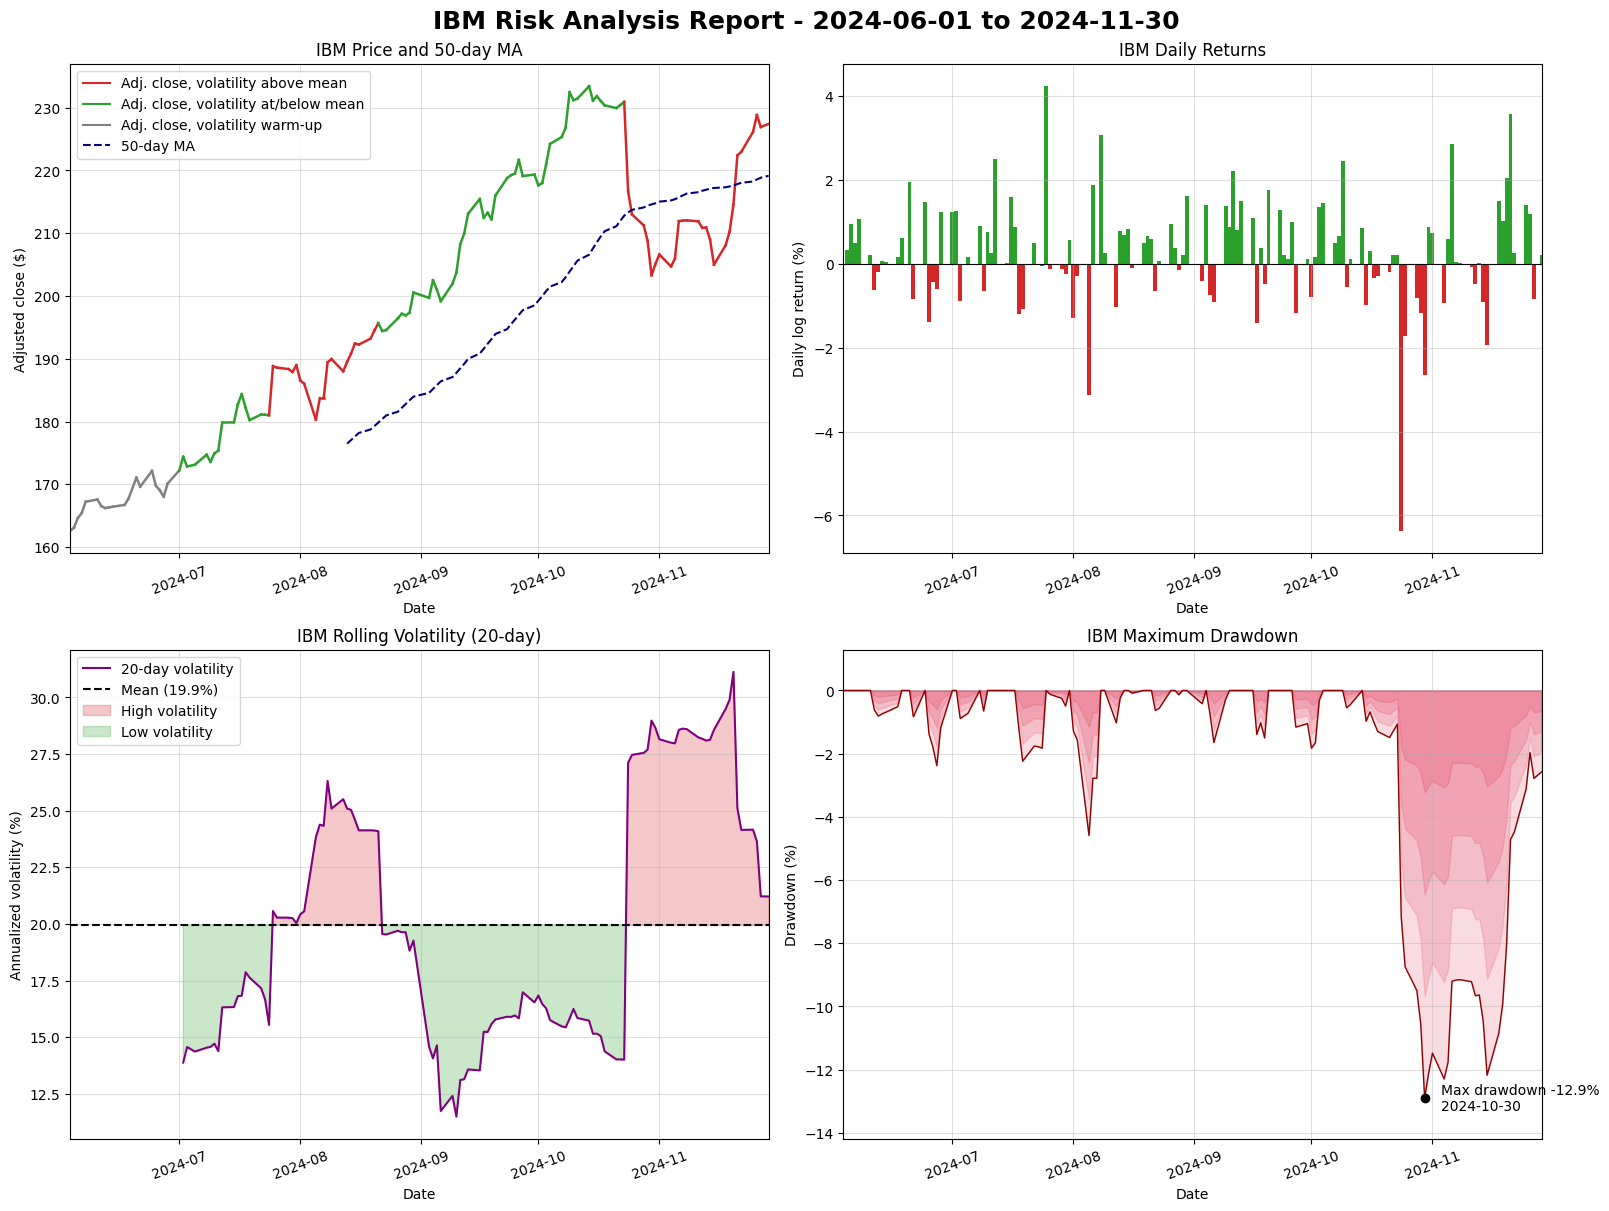

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12), layout="constrained")
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18, fontweight="bold")
mean_volatility = df["volatility"].mean()
vol_colors = {"high": "#d62728", "low": "#2ca02c", "warm-up": "gray"}

# Top left: price segments colored by that day's rolling volatility vs the report mean
ax = axes[0, 0]
for i in range(1, len(df)):
    vol = df["volatility"].iloc[i]
    color = vol_colors["warm-up"] if pd.isna(vol) else (
        vol_colors["high"] if vol > mean_volatility else vol_colors["low"])
    ax.plot(df.index[i - 1:i + 1], df["adj_close"].iloc[i - 1:i + 1], color=color, linewidth=1.8)
ax.plot(df.index, df["sma_50"], color="navy", linestyle="--", linewidth=1.5)
ax.legend(handles=[
    Line2D([], [], color=vol_colors["high"], label="Adj. close, volatility above mean"),
    Line2D([], [], color=vol_colors["low"], label="Adj. close, volatility at/below mean"),
    Line2D([], [], color=vol_colors["warm-up"], label="Adj. close, volatility warm-up"),
    Line2D([], [], color="navy", linestyle="--",
           label="50-day MA" if df["sma_50"].notna().any() else "50-day MA (needs 50 prices)"),
], loc="best")
ax.set(title=f"{ticker} Price and 50-day MA", ylabel="Adjusted close ($)")

# Top right: daily log returns, green up / red down
ax = axes[0, 1]
returns_pct = df["log_return"] * 100
ax.bar(df.index, returns_pct, width=1.0,
       color=np.where(returns_pct.ge(0), vol_colors["low"], vol_colors["high"]))
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title=f"{ticker} Daily Returns", ylabel="Daily log return (%)")

# Bottom left: rolling volatility, mean line, shaded above/below the mean
ax = axes[1, 0]
vol_pct = df["volatility"] * 100
ax.plot(df.index, vol_pct, color="purple", linewidth=1.5, label=f"{VOLATILITY_WINDOW}-day volatility")
ax.axhline(mean_volatility * 100, color="black", linestyle="--", label=f"Mean ({mean_volatility:.1%})")
ax.fill_between(df.index, vol_pct, mean_volatility * 100, where=df["volatility"] > mean_volatility,
                color=vol_colors["high"], alpha=0.25, interpolate=True, label="High volatility")
ax.fill_between(df.index, vol_pct, mean_volatility * 100, where=df["volatility"] <= mean_volatility,
                color=vol_colors["low"], alpha=0.25, interpolate=True, label="Low volatility")
ax.legend(loc="best")
ax.set(title=f"{ticker} Rolling Volatility ({VOLATILITY_WINDOW}-day)", ylabel="Annualized volatility (%)")

# Bottom right: drawdown area, layered transparent fills for a red gradient
ax = axes[1, 1]
drawdown_pct = df["drawdown"] * 100
for fraction in [1.0, 0.75, 0.5, 0.25]:
    ax.fill_between(df.index, drawdown_pct * fraction, 0, color="crimson", alpha=0.15)
ax.plot(df.index, drawdown_pct, color="darkred", linewidth=1)
worst_date = df["drawdown"].idxmin()
ax.scatter([worst_date], [drawdown_pct.loc[worst_date]], color="black", zorder=3)
ax.annotate(f"Max drawdown {drawdown_pct.loc[worst_date]:.1f}%\n{worst_date.date()}",
            (worst_date, drawdown_pct.loc[worst_date]), xytext=(12, 0), textcoords="offset points", va="center")
ax.margins(y=0.1)
ax.set(title=f"{ticker} Maximum Drawdown", ylabel="Drawdown (%)")

for ax in axes.flat:
    ax.set_xlim(df.index.min(), df.index.max())
    ax.set_xlabel("Date")
    ax.grid(True, alpha=0.4)
    ax.tick_params(axis="x", labelrotation=20)
plt.show()

## 2.5 Summary statistics

Total Return · Annualized Return · Annualized Volatility · Sharpe Ratio · Maximum Drawdown · Best Day · Worst Day · Positive Days · Average Up Day · Average Down Day

- Total return = `last_adj_close / first_adj_close - 1`
- Annualized return = `exp(sum(log_returns) * 252 / n) - 1`, with `n` nonmissing log returns
- Annualized volatility = `std(log_returns) * sqrt(252)` (whole period, not the rolling mean)
- Positive days = positive returns / all nonmissing returns; empty up/down subsets show `N/A`

In [8]:
n_returns = len(log_returns)  # nonmissing returns only
summary_metrics = pd.Series({
    "Total Return": df["adj_close"].iloc[-1] / df["adj_close"].iloc[0] - 1,
    "Annualized Return": np.exp(log_returns.sum() * 252 / n_returns) - 1,
    "Annualized Volatility": log_returns.std() * np.sqrt(252),  # whole period, not the rolling mean
    "Sharpe Ratio": sharpe_ratio,
    "Maximum Drawdown": max_drawdown,
    "Best Day": log_returns.max(),
    "Worst Day": log_returns.min(),
    "Positive Days": log_returns.gt(0).sum() / n_returns,  # zero days stay in the denominator
    "Average Up Day": log_returns[log_returns > 0].mean(),  # NaN if there are no up days
    "Average Down Day": log_returns[log_returns < 0].mean(),
})

SIGNED_METRICS = {"Total Return", "Annualized Return", "Maximum Drawdown", "Best Day",
                  "Worst Day", "Average Up Day", "Average Down Day"}


def format_metric(name: str, value: float) -> str:
    """Format one fractional metric for display; undefined values show N/A."""
    if pd.isna(value):
        return "N/A"
    if name == "Sharpe Ratio":
        return f"{value:.2f}"
    if name == "Positive Days":
        return f"{value:.1%}"
    return f"{value:+.2%}" if name in SIGNED_METRICS else f"{value:.2%}"


summary_table = pd.DataFrame({"Metric": summary_metrics.index,
                              "Value": [format_metric(k, v) for k, v in summary_metrics.items()]})
print(f"{ticker} summary, {first_date} to {last_date} ({n_returns} daily log returns)\n")
print(summary_table.to_string(index=False))

IBM summary, 2024-06-03 to 2024-11-29 (125 daily log returns)

               Metric   Value
         Total Return +39.88%
    Annualized Return +96.73%
Annualized Volatility  20.42%
         Sharpe Ratio    3.22
     Maximum Drawdown -12.90%
             Best Day  +4.24%
            Worst Day  -6.37%
        Positive Days   63.2%
       Average Up Day  +0.95%
     Average Down Day  -0.92%


## Outputs for the batch

Save the named metrics `03_run_all_stocks.py` collects (e.g. with `sb.glue`): `avg_daily_return`, `avg_volatility`, `max_drawdown`, `sharpe_ratio`, `total_return`, plus ticker and actual coverage dates.

In [9]:
sb.glue("ticker", ticker)
sb.glue("start_date", start_date)
sb.glue("end_date", end_date)
sb.glue("first_date", str(first_date))
sb.glue("last_date", str(last_date))
sb.glue("trading_days", len(df))
sb.glue("avg_daily_return", float(log_returns.mean()))
sb.glue("avg_volatility", float(df["volatility"].mean()))
sb.glue("max_drawdown", float(max_drawdown))
sb.glue("sharpe_ratio", float(sharpe_ratio))
sb.glue("total_return", float(summary_metrics["Total Return"]))